# Experiment 01: Blend of the final MLP and lgbm_building

Card: [exp01_final_blend.md](../../experiments/exp01_final_blend.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "../../..")  # the homework folder: the ashrae package and other sections' src
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.plots import GRID, MUTED, SURFACE, TEXT
from mlp.src.data import make_loaders
from mlp.src.networks import MeterMLP
from mlp.src.predict import predict
from mlp.src.tracking import Experiment

# Imported after torch: loading LightGBM first crashes the kernel on macOS (both ship an OpenMP runtime).
import lightgbm as lgb

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp01_final_blend"
MLP, LGBM, BLEND = "mlp_4out_emb_bn", "lgbm_building", "blend"
EMB_DIM, WIDTH, DROPOUT, N_LAYERS, LR = (
    12,
    64,
    0.1,
    2,
    1e-2,
)  # the final model, mlp exp18
if SMOKE:
    EXPERIMENT = "ashrae-ensemble-final-blend-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]  # two folds: leave-one-fold-out needs another fold
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 4
    LGBM_PARAMS = {"n_estimators": 10, "learning_rate": 0.1, "num_leaves": 63}
    WEIGHTS = np.round(np.linspace(0, 1, 5), 2)
    FIGURE = None
else:
    EXPERIMENT = "ashrae-ensemble-final-blend"
    TRAIN = False  # the runs below are from 2026-10-13; True retrains them under a new session
    SESSION = "2026-10-13 12:40:27"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    LGBM_PARAMS = {
        "n_estimators": 500,
        "learning_rate": 0.1,
        "num_leaves": 63,
    }  # baseline exp01
    WEIGHTS = np.round(np.linspace(0, 1, 21), 2)  # weight of the MLP
    FIGURE = "../../figures/exp01_final_blend.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, None if TRAIN else SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-ensemble-final-blend', session 2026-10-13 12:40:27


## Training


In [2]:
def step_schedule(params):
    """Adam at LR, divided by 10 at half and three quarters of training (the step schedule of mlp exp17)."""
    opt = torch.optim.Adam(params, lr=LR)
    sched = torch.optim.lr_scheduler.MultiStepLR(
        opt, milestones=[EPOCHS // 2, EPOCHS * 3 // 4], gamma=0.1
    )
    return {"optimizer": opt, "lr_scheduler": {"scheduler": sched, "interval": "epoch"}}


def blend(d, w):
    """Weighted average in log1p space, the space RMSLE is measured in."""
    return w * d["pred"][MLP] + (1 - w) * d["pred"][LGBM]


if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    BUILDING = pd.CategoricalDtype(
        range(n_buildings)
    )  # all ids, so every fold shares categories
    params = {"n_train": N_TRAIN, "n_val": N_VAL}

    oof = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        y_train = np.log1p(train_df.meter_reading.to_numpy(dtype="float32"))
        y_val = np.log1p(val_df.meter_reading.to_numpy(dtype="float32"))

        train_loader, val_loader, _ = make_loaders(train_df, val_df, X_train, X_val)
        model, _ = experiment.fit(
            lambda: MeterMLP(
                X_train.shape[1],
                n_buildings,
                emb_dim=EMB_DIM,
                batch_norm=True,
                dropout=DROPOUT,
                width=WIDTH,
                n_layers=N_LAYERS,
            ),
            train_loader,
            val_loader,
            run_name=f"{MLP} | {fold}",
            epochs=EPOCHS,
            lr=LR,
            optimizer=step_schedule,
            tags={"fold": fold, "model": MLP},
            params={
                **params,
                "emb_dim": EMB_DIM,
                "width": WIDTH,
                "dropout": DROPOUT,
                "n_layers": N_LAYERS,
                "schedule": "step",
            },
        )

        to_cat = lambda X, rows: X.assign(
            building_id=rows.building_id.astype(int).astype(BUILDING).to_numpy()
        )
        # n_jobs=1: multi-threaded LightGBM segfaults once torch has loaded its OpenMP runtime
        gbm = lgb.LGBMRegressor(
            **LGBM_PARAMS, random_state=0, verbose=-1, n_jobs=1
        ).fit(to_cat(X_train, train_df), y_train)
        oof[fold] = {
            "y": y_val,
            "pred": {
                MLP: predict(model, val_loader),
                LGBM: np.clip(gbm.predict(to_cat(X_val, val_df)), 0, None),
            },
        }
        experiment.log_run(
            f"{LGBM} | {fold}",
            params={**params, **LGBM_PARAMS},
            tags={"fold": fold, "model": LGBM},
            metrics={"val_rmsle": rmsle(y_val, oof[fold]["pred"][LGBM])},
        )
    del df

    # leave one fold out: each fold's weight is chosen on the other folds
    curve = pd.DataFrame(
        {
            fold: [rmsle(d["y"], blend(d, w)) for w in WEIGHTS]
            for fold, d in oof.items()
        },
        index=WEIGHTS,
    )
    for fold, d in oof.items():
        w = float(curve.drop(columns=fold).mean(axis=1).idxmin())
        experiment.log_run(
            f"{BLEND} | {fold}",
            params={**params, "mlp_weight": w},
            tags={"fold": fold, "model": BLEND},
            metrics={"val_rmsle": rmsle(d["y"], blend(d, w))},
        )

## Results


In [3]:
runs = experiment.runs().sort_values("start_time")
runs = runs.drop_duplicates(
    "tags.mlflow.runName", keep="last"
)  # a re-logged run replaces the earlier one
runs = runs[runs["tags.fold"].isin(FOLD_NAMES)]
print(f"MLflow session {experiment.session}: {len(runs)} runs")
print(
    "MLP weight per fold:",
    runs.dropna(subset="params.mlp_weight")
    .set_index("tags.fold")["params.mlp_weight"]
    .to_dict(),
)
scores = runs.groupby("tags.model")["metrics.val_rmsle"].mean().loc[[LGBM, MLP, BLEND]]

MLflow session 2026-10-13 12:40:27: 12 runs
MLP weight per fold: {'Jan–Mar': '0.8', 'Apr–Jun': '0.8', 'Jul–Sep': '0.75', 'Oct–Dec': '0.8'}


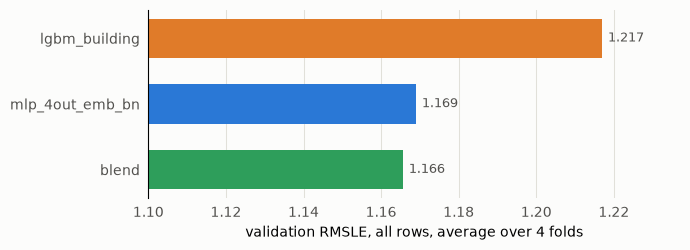

In [4]:
COLORS = {LGBM: "#e07b29", MLP: "#2a78d6", BLEND: "#2e9e5b"}  # orange, blue, green
BASE = 1.1  # bars start here, so the differences between models are visible

fig, ax = plt.subplots(figsize=(7, 2.6), facecolor=SURFACE)
y = np.arange(len(scores))[::-1]
bars = ax.barh(
    y, scores - BASE, left=BASE, height=0.6, color=[COLORS[m] for m in scores.index]
)
ax.bar_label(
    bars, labels=[f"{v:.3f}" for v in scores], padding=4, fontsize=9, color=TEXT
)
ax.set(
    yticks=y,
    yticklabels=scores.index,
    xlim=(BASE, scores.max() + 0.02),
    xlabel=f"validation RMSLE, all rows, average over {len(FOLD_NAMES)} folds",
)
ax.set_facecolor(SURFACE)
ax.grid(axis="x", color=GRID, lw=0.75)
ax.set_axisbelow(True)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
fig.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in runs.run_id:
        experiment.client.log_artifact(run_id, FIGURE)